In [149]:
import pandas as pd  
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.model_selection import train_test_split 
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score


# Load Dataset

In [150]:
df = pd.read_csv('Ecommerce_Sales_Prediction_Dataset.csv')



# Data Cleaning 

In [4]:
df.head()

,Date,Product_Category,Price,Discount,Customer_Segment,Marketing_Spend,Units_Sold
0,01-01-2023,Sports,932.80,35.82,Occasional,6780.38,32
1,02-01-2023,Toys,569.48,3.60,Premium,6807.56,16
2,03-01-2023,Home Decor,699.68,3.56,Premium,3793.91,27
3,04-01-2023,Toys,923.27,0.61,Premium,9422.75,29
4,05-01-2023,Toys,710.17,47.83,Premium,1756.83,17


In [7]:
df =df. drop_duplicates() 
df

,Date,Product_Category,Price,Discount,Customer_Segment,Marketing_Spend,Units_Sold
0,01-01-2023,Sports,932.80,35.82,Occasional,6780.38,32
1,02-01-2023,Toys,569.48,3.60,Premium,6807.56,16
2,03-01-2023,Home Decor,699.68,3.56,Premium,3793.91,27
3,04-01-2023,Toys,923.27,0.61,Premium,9422.75,29
4,05-01-2023,Toys,710.17,47.83,Premium,1756.83,17
...,...,...,...,...,...,...,...
995,22-09-2025,Fashion,740.06,49.06,Regular,1890.83,34
996,23-09-2025,Electronics,517.10,28.48,Premium,8011.66,21
997,24-09-2025,Electronics,683.43,12.98,Occasional,3408.51,19
998,25-09-2025,Sports,51.26,21.85,Occasional,7335.62,26


In [8]:
df.isnull().sum()

Date                0
Product_Category    0
Price               0
Discount            0
Customer_Segment    0
Marketing_Spend     0
Units_Sold          0
dtype: int64

# Feature Engineering

In [15]:
df = df.dropna() 
df

,Date,Product_Category,Price,Discount,Customer_Segment,Marketing_Spend,Units_Sold
0,01-01-2023,Sports,932.80,35.82,Occasional,6780.38,32
1,02-01-2023,Toys,569.48,3.60,Premium,6807.56,16
2,03-01-2023,Home Decor,699.68,3.56,Premium,3793.91,27
3,04-01-2023,Toys,923.27,0.61,Premium,9422.75,29
4,05-01-2023,Toys,710.17,47.83,Premium,1756.83,17
...,...,...,...,...,...,...,...
995,22-09-2025,Fashion,740.06,49.06,Regular,1890.83,34
996,23-09-2025,Electronics,517.10,28.48,Premium,8011.66,21
997,24-09-2025,Electronics,683.43,12.98,Occasional,3408.51,19
998,25-09-2025,Sports,51.26,21.85,Occasional,7335.62,26


In [17]:
print(df['Date'].head(10))

0    01-01-2023
1    02-01-2023
2    03-01-2023
3    04-01-2023
4    05-01-2023
5    06-01-2023
6    07-01-2023
7    08-01-2023
8    09-01-2023
9    10-01-2023
Name: Date, dtype: object


In [18]:
print(df['Date'].dtype)

object


In [19]:
print(df['Date'].isnull().sum())

0


In [158]:
df['Date'] = pd.to_datetime(df['Date'],dayfirst=True, errors='coerce')

In [159]:
df['Year'] = df['Date'].dt.year 
df['Month'] = df['Date'].dt.month 
df['Day'] = df['Date'].dt.day

In [27]:
df['Lag_1'] = df['Units_Sold'].shift(1)  
df['Lag_7'] = df['Units_Sold'].shift(7)  

In [28]:
df['Rolling_Avg'] = df['Units_Sold'].rolling(7).mean()

In [29]:
df = df.dropna() 
df

,Date,Product_Category,Price,Discount,Customer_Segment,Marketing_Spend,Units_Sold,Year,Month,Day,Lag_1,Lag_7,Rolling_Avg
7,2023-01-08,Home Decor,610.65,14.83,Regular,7001.64,27,2023,1,8,30.0,32.0,24.714286
8,2023-01-09,Home Decor,429.89,17.49,Occasional,6521.53,32,2023,1,9,27.0,16.0,27.000000
9,2023-01-10,Toys,739.08,38.73,Regular,2825.35,28,2023,1,10,32.0,27.0,27.142857
10,2023-01-11,Sports,935.02,33.07,Premium,1646.45,26,2023,1,11,28.0,29.0,26.714286
11,2023-01-12,Home Decor,926.31,9.26,Regular,6395.81,26,2023,1,12,26.0,17.0,28.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,2025-09-22,Fashion,740.06,49.06,Regular,1890.83,34,2025,9,22,26.0,21.0,31.285714
996,2025-09-23,Electronics,517.10,28.48,Premium,8011.66,21,2025,9,23,34.0,23.0,31.000000
997,2025-09-24,Electronics,683.43,12.98,Occasional,3408.51,19,2025,9,24,21.0,33.0,29.000000
998,2025-09-25,Sports,51.26,21.85,Occasional,7335.62,26,2025,9,25,19.0,26.0,29.000000


# Exploratory Data Analysis

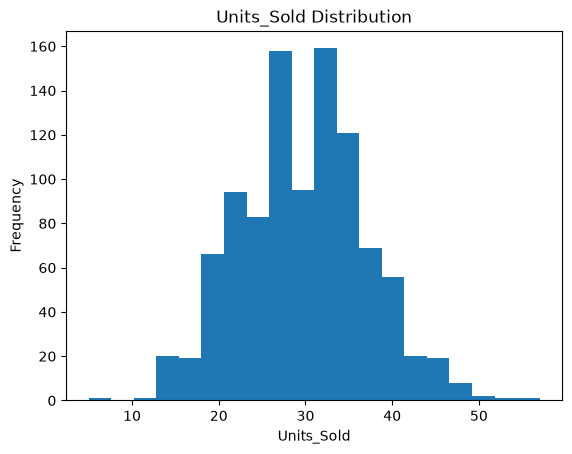

In [31]:
plt.hist(df['Units_Sold'], bins=20) 
plt.xlabel('Units_Sold') 
plt.ylabel('Frequency') 
plt.title('Units_Sold Distribution') 
plt.show()
          

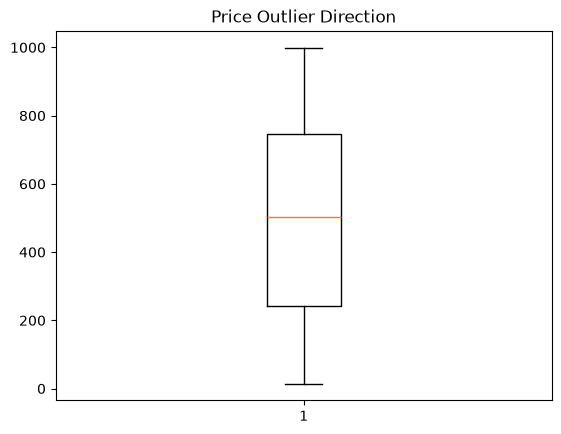

In [34]:
plt.boxplot(df['Price']) 
plt.title('Price Outlier Direction') 
plt.show()

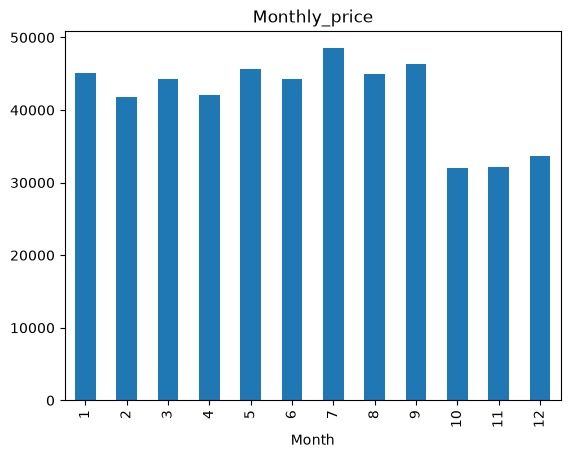

In [35]:
monthly_price = df.groupby('Month')['Price'].sum() 

monthly_price.plot(kind='bar') 
plt.title('Monthly_price') 
plt.show()

# Encode Categorical Variables 

In [36]:
df = pd.get_dummies(df, columns=['Product_Category','Customer_Segment'],drop_first=True)

# Prepare X and Y 

In [160]:
x = df.drop(['Date','Units_Sold'], axis=1) 

y = df['Units_Sold']

# Train Test Split 

In [84]:
split = int(len(df) * 0.8) 

x_train = x.iloc[:split] 
x_test = x.iloc[split:]  

y_train = x.iloc[:split]  
x_test = x.iloc[split:]

In [85]:
rf = RandomForestClassifier()  

In [41]:
x_train

,Price,Discount,Marketing_Spend,Year,Month,Day,Lag_1,Lag_7,Rolling_Avg,Product_Category_Fashion,Product_Category_Home Decor,Product_Category_Sports,Product_Category_Toys,Customer_Segment_Premium,Customer_Segment_Regular
7,610.65,14.83,7001.64,2023,1,8,30.0,32.0,24.714286,False,True,False,False,False,True
8,429.89,17.49,6521.53,2023,1,9,27.0,16.0,27.000000,False,True,False,False,False,False
9,739.08,38.73,2825.35,2023,1,10,32.0,27.0,27.142857,False,False,False,True,False,True
10,935.02,33.07,1646.45,2023,1,11,28.0,29.0,26.714286,False,False,True,False,True,False
11,926.31,9.26,6395.81,2023,1,12,26.0,17.0,28.000000,False,True,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
796,137.11,27.63,1292.43,2025,3,7,31.0,28.0,28.285714,False,False,False,True,False,False
797,113.07,26.01,5886.98,2025,3,8,27.0,24.0,27.571429,True,False,False,False,True,False
798,727.10,7.14,9696.29,2025,3,9,19.0,32.0,27.428571,False,True,False,False,False,False
799,582.60,38.77,3840.61,2025,3,10,31.0,15.0,29.857143,False,True,False,False,True,False


In [42]:
y_train

,Price,Discount,Marketing_Spend,Year,Month,Day,Lag_1,Lag_7,Rolling_Avg,Product_Category_Fashion,Product_Category_Home Decor,Product_Category_Sports,Product_Category_Toys,Customer_Segment_Premium,Customer_Segment_Regular
7,610.65,14.83,7001.64,2023,1,8,30.0,32.0,24.714286,False,True,False,False,False,True
8,429.89,17.49,6521.53,2023,1,9,27.0,16.0,27.000000,False,True,False,False,False,False
9,739.08,38.73,2825.35,2023,1,10,32.0,27.0,27.142857,False,False,False,True,False,True
10,935.02,33.07,1646.45,2023,1,11,28.0,29.0,26.714286,False,False,True,False,True,False
11,926.31,9.26,6395.81,2023,1,12,26.0,17.0,28.000000,False,True,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
796,137.11,27.63,1292.43,2025,3,7,31.0,28.0,28.285714,False,False,False,True,False,False
797,113.07,26.01,5886.98,2025,3,8,27.0,24.0,27.571429,True,False,False,False,True,False
798,727.10,7.14,9696.29,2025,3,9,19.0,32.0,27.428571,False,True,False,False,False,False
799,582.60,38.77,3840.61,2025,3,10,31.0,15.0,29.857143,False,True,False,False,True,False


# Model Evaluation 

In [47]:
print(x_train.dtypes)

Price                          float64
Discount                       float64
Marketing_Spend                float64
Year                             int32
Month                            int32
Day                              int32
Lag_1                          float64
Lag_7                          float64
Rolling_Avg                    float64
Product_Category_Fashion          bool
Product_Category_Home Decor       bool
Product_Category_Sports           bool
Product_Category_Toys             bool
Customer_Segment_Premium          bool
Customer_Segment_Regular          bool
dtype: object


In [48]:
print(x_train.isnull().sum()) 
print(x_test.isnull().sum()) 
      

Price                          0
Discount                       0
Marketing_Spend                0
Year                           0
Month                          0
Day                            0
Lag_1                          0
Lag_7                          0
Rolling_Avg                    0
Product_Category_Fashion       0
Product_Category_Home Decor    0
Product_Category_Sports        0
Product_Category_Toys          0
Customer_Segment_Premium       0
Customer_Segment_Regular       0
dtype: int64
Price                          0
Discount                       0
Marketing_Spend                0
Year                           0
Month                          0
Day                            0
Lag_1                          0
Lag_7                          0
Rolling_Avg                    0
Product_Category_Fashion       0
Product_Category_Home Decor    0
Product_Category_Sports        0
Product_Category_Toys          0
Customer_Segment_Premium       0
Customer_Segment_Regular      

In [49]:
df = df.dropna() 
df

,Date,Price,Discount,Marketing_Spend,Units_Sold,Year,Month,Day,Lag_1,Lag_7,Rolling_Avg,Product_Category_Fashion,Product_Category_Home Decor,Product_Category_Sports,Product_Category_Toys,Customer_Segment_Premium,Customer_Segment_Regular
7,2023-01-08,610.65,14.83,7001.64,27,2023,1,8,30.0,32.0,24.714286,False,True,False,False,False,True
8,2023-01-09,429.89,17.49,6521.53,32,2023,1,9,27.0,16.0,27.000000,False,True,False,False,False,False
9,2023-01-10,739.08,38.73,2825.35,28,2023,1,10,32.0,27.0,27.142857,False,False,False,True,False,True
10,2023-01-11,935.02,33.07,1646.45,26,2023,1,11,28.0,29.0,26.714286,False,False,True,False,True,False
11,2023-01-12,926.31,9.26,6395.81,26,2023,1,12,26.0,17.0,28.000000,False,True,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,2025-09-22,740.06,49.06,1890.83,34,2025,9,22,26.0,21.0,31.285714,True,False,False,False,False,True
996,2025-09-23,517.10,28.48,8011.66,21,2025,9,23,34.0,23.0,31.000000,False,False,False,False,True,False
997,2025-09-24,683.43,12.98,3408.51,19,2025,9,24,21.0,33.0,29.000000,False,False,False,False,False,False
998,2025-09-25,51.26,21.85,7335.62,26,2025,9,25,19.0,26.0,29.000000,False,False,True,False,False,False


In [110]:
from sklearn.ensemble import RandomForestRegressor 

rf = RandomForestRegressor() 


In [162]:
x_train

,Price,Discount,Marketing_Spend,Year,Month,Day
29,920.66,26.52,1621.54,2023,1,30
535,722.01,2.98,1044.07,2024,6,19
695,379.52,10.16,1124.00,2024,11,26
557,728.01,43.68,6829.00,2024,7,11
836,668.26,0.22,5812.12,2025,4,16
...,...,...,...,...,...,...
106,189.62,38.05,4929.56,2023,4,17
270,246.39,10.07,8362.26,2023,9,28
860,558.26,41.11,9414.71,2025,5,10
435,237.66,2.41,9172.56,2024,3,11


In [163]:
y_train

29     25
535    29
695    31
557    35
836    23
       ..
106    31
270    25
860    20
435    37
102    28
Name: Units_Sold, Length: 800, dtype: int64

In [72]:
rf.fit(x_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the numb

# Model Evaluation 

In [77]:
y_pred = rf.predict(x_test) 
y_pred

array([[1.3708610e+02, 2.9871800e+01, 3.5046840e+03, ..., 2.6000000e-01,
        5.0000000e-02, 7.2000000e-01],
       [1.0810400e+02, 2.2312600e+01, 5.1190201e+03, ..., 3.0000000e-02,
        9.0000000e-02, 7.6000000e-01],
       [9.1168400e+02, 2.3019700e+01, 1.6894406e+03, ..., 0.0000000e+00,
        5.6000000e-01, 3.8000000e-01],
       ...,
       [7.0357520e+02, 2.2209700e+01, 3.3964835e+03, ..., 6.0000000e-02,
        2.2000000e-01, 6.0000000e-01],
       [1.1630020e+02, 2.3863400e+01, 7.2901565e+03, ..., 2.3000000e-01,
        4.6000000e-01, 3.5000000e-01],
       [1.6466750e+02, 2.2183600e+01, 4.2453269e+03, ..., 2.4000000e-01,
        4.0000000e-01, 3.4000000e-01]], shape=(199, 15))

In [63]:
y_train

,Price,Discount,Marketing_Spend,Year,Month,Day,Lag_1,Lag_7,Rolling_Avg,Product_Category_Fashion,Product_Category_Home Decor,Product_Category_Sports,Product_Category_Toys,Customer_Segment_Premium,Customer_Segment_Regular
7,610.65,14.83,7001.64,2023,1,8,30.0,32.0,24.714286,False,True,False,False,False,True
8,429.89,17.49,6521.53,2023,1,9,27.0,16.0,27.000000,False,True,False,False,False,False
9,739.08,38.73,2825.35,2023,1,10,32.0,27.0,27.142857,False,False,False,True,False,True
10,935.02,33.07,1646.45,2023,1,11,28.0,29.0,26.714286,False,False,True,False,True,False
11,926.31,9.26,6395.81,2023,1,12,26.0,17.0,28.000000,False,True,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
796,137.11,27.63,1292.43,2025,3,7,31.0,28.0,28.285714,False,False,False,True,False,False
797,113.07,26.01,5886.98,2025,3,8,27.0,24.0,27.571429,True,False,False,False,True,False
798,727.10,7.14,9696.29,2025,3,9,19.0,32.0,27.428571,False,True,False,False,False,False
799,582.60,38.77,3840.61,2025,3,10,31.0,15.0,29.857143,False,True,False,False,True,False


In [101]:
y_train

,Price,Discount,Marketing_Spend,Year,Month,Day,Lag_1,Lag_7,Rolling_Avg,Product_Category_Fashion,Product_Category_Home Decor,Product_Category_Sports,Product_Category_Toys,Customer_Segment_Premium,Customer_Segment_Regular
7,610.65,14.83,7001.64,2023,1,8,30.0,32.0,24.714286,False,True,False,False,False,True
8,429.89,17.49,6521.53,2023,1,9,27.0,16.0,27.000000,False,True,False,False,False,False
9,739.08,38.73,2825.35,2023,1,10,32.0,27.0,27.142857,False,False,False,True,False,True
10,935.02,33.07,1646.45,2023,1,11,28.0,29.0,26.714286,False,False,True,False,True,False
11,926.31,9.26,6395.81,2023,1,12,26.0,17.0,28.000000,False,True,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
796,137.11,27.63,1292.43,2025,3,7,31.0,28.0,28.285714,False,False,False,True,False,False
797,113.07,26.01,5886.98,2025,3,8,27.0,24.0,27.571429,True,False,False,False,True,False
798,727.10,7.14,9696.29,2025,3,9,19.0,32.0,27.428571,False,True,False,False,False,False
799,582.60,38.77,3840.61,2025,3,10,31.0,15.0,29.857143,False,True,False,False,True,False


In [106]:
print(len(y_test))
print(len(y_pred))

199
199


In [107]:
split = int(len(df) * 0.8) 

x_train = x.iloc[:split] 
x_test = x.iloc[split:]  

y_train = x.iloc[:split]  
x_test = x.iloc[split:]

In [116]:
print(x.shape) 
print(y.shape)

(993, 15)
(993,)


In [161]:
from sklearn.model_selection import train_test_split      

x_train,x_test,y_train,y_test = train_test_split(
    x,y,test_size=0.2,random_state=42
) 


In [123]:
df.head()

,Date,Product_Category,Price,Discount,Customer_Segment,Marketing_Spend,Units_Sold
0,01-01-2023,Sports,932.80,35.82,Occasional,6780.38,32
1,02-01-2023,Toys,569.48,3.60,Premium,6807.56,16
2,03-01-2023,Home Decor,699.68,3.56,Premium,3793.91,27
3,04-01-2023,Toys,923.27,0.61,Premium,9422.75,29
4,05-01-2023,Toys,710.17,47.83,Premium,1756.83,17


In [151]:
df = df.drop(['Customer_Segment'],axis=1) 

In [153]:
df = df.drop(['Product_Category'], axis=1)

In [154]:
df.head()

,Date,Price,Discount,Marketing_Spend,Units_Sold
0,01-01-2023,932.80,35.82,6780.38,32
1,02-01-2023,569.48,3.60,6807.56,16
2,03-01-2023,699.68,3.56,3793.91,27
3,04-01-2023,923.27,0.61,9422.75,29
4,05-01-2023,710.17,47.83,1756.83,17


In [164]:
from sklearn.ensemble import RandomForestRegressor 

rf = RandomForestRegressor()  

rf.fit(x_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the numb

In [166]:
y_pred = rf.predict(x_test) 
y_pred

array([26.73, 29.73, 29.48, 32.5 , 24.55, 32.61, 26.5 , 34.02, 28.02,
       30.03, 26.85, 32.05, 30.02, 27.64, 30.27, 31.79, 29.01, 25.97,
       29.94, 31.97, 26.01, 29.93, 29.54, 27.23, 30.66, 29.42, 28.29,
       29.07, 26.82, 27.4 , 31.02, 27.11, 32.56, 33.3 , 29.13, 25.72,
       30.19, 21.72, 31.09, 29.3 , 31.47, 28.73, 30.01, 29.45, 27.4 ,
       30.48, 34.06, 32.78, 30.74, 27.94, 29.41, 30.76, 34.53, 29.69,
       33.69, 29.82, 32.6 , 28.72, 30.23, 28.92, 31.18, 27.4 , 30.74,
       33.44, 31.67, 27.99, 29.58, 33.24, 31.77, 30.53, 29.18, 31.46,
       27.  , 29.62, 31.78, 28.86, 29.13, 31.71, 30.45, 32.4 , 29.64,
       30.4 , 31.96, 28.22, 28.09, 28.22, 30.76, 28.28, 28.9 , 29.34,
       28.48, 26.68, 28.87, 29.9 , 31.24, 28.36, 29.66, 30.29, 29.6 ,
       30.38, 27.31, 31.4 , 31.1 , 28.98, 28.85, 31.34, 28.93, 28.99,
       35.07, 28.11, 30.86, 29.07, 28.53, 30.69, 31.68, 32.06, 33.95,
       31.04, 29.55, 31.05, 29.89, 28.02, 35.39, 31.88, 30.8 , 33.6 ,
       27.06, 31.95,

In [167]:
from sklearn.metrics import r2_score 

print(r2_score(y_test, y_pred))

-0.1201756719089968


In [169]:
print('MAE', mean_absolute_error(y_test, y_pred))

MAE 6.1513


In [170]:
print('MSE', mean_squared_error(y_test, y_pred))

MSE 60.58332899999999


# Business insights 

In [ ]:
1. Identify periods with highest and lowest sales
2. Understand monthly sales Fluctuations 
3. Understand discount in the sales 
4. Identify top selling products 
5. Understand products sales in months 